# Cloud Workload Forecasting - Holdout Evaluation

The model was chosen in `02_modeling` using the training window only.
Here I score it once on the 24-step holdout. I do not change the model after seeing these results.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from cwfc.data import build_targets, load_readings, split_train_holdout
from cwfc.metrics import mae, normalized_mae, rmse, smape
from cwfc.models import persistence_forecast
from cwfc.pipeline import make_predictions

data_dir = Path("challenge_data")
if not data_dir.exists():
    data_dir = Path("../challenge_data")

targets = build_targets(load_readings(data_dir))
train, holdout = split_train_holdout(targets)
predictions = make_predictions(targets)

results = holdout[["timestamp"]].copy()
results["actual"] = holdout["aggregate_cpu_utilization"].to_numpy()
results["model"] = predictions["aggregate_cpu_utilization"].to_numpy()
results["persistence"] = persistence_forecast(train["aggregate_cpu_utilization"].to_numpy(), len(holdout))

## 1. Overall accuracy

In [2]:
rows = {}
for name in ["model", "persistence"]:
    rows[name] = {
        "mae": mae(results["actual"], results[name]),
        "rmse": rmse(results["actual"], results[name]),
        "smape_%": smape(results["actual"], results[name]),
        "max_abs_error": float((results["actual"] - results[name]).abs().max()),
    }
metrics = pd.DataFrame(rows).T
metrics["mae_vs_persistence"] = [
    normalized_mae(results["actual"], results[name], results["persistence"]) for name in metrics.index
]
display(metrics.round(4))

print("Active VM count MAE:", mae(holdout["active_vm_count"], predictions["active_vm_count"]))

,mae,rmse,smape_%,max_abs_error,mae_vs_persistence
model,0.0981,0.1193,1.0577,0.3061,0.6683
persistence,0.1468,0.1848,1.5851,0.4714,1.0000


Active VM count MAE: 0.0


**What I see:**
- The model beats persistence on every metric: MAE 0.098 vs 0.147 (33% lower), RMSE 0.119 vs 0.185,
  sMAPE 1.06% vs 1.59%, max error 0.31 vs 0.47 points.
- Holdout error is about half the validation error (0.098 vs 0.198). The holdout is a calmer period than
  the bump in the training window. With only 24 points, I do not read this as a true improvement.
- The VM count forecast is exact (MAE 0) because the count is constant.

## 2. Forecast vs actual

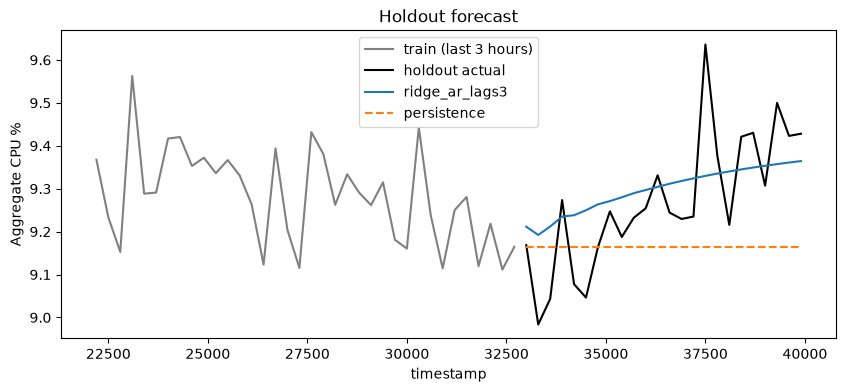

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
recent_train = train.tail(36)
ax.plot(recent_train["timestamp"], recent_train["aggregate_cpu_utilization"], color="gray", label="train (last 3 hours)")
ax.plot(results["timestamp"], results["actual"], color="black", label="holdout actual")
ax.plot(results["timestamp"], results["model"], label="ridge_ar_lags3")
ax.plot(results["timestamp"], results["persistence"], linestyle="--", label="persistence")
ax.set_xlabel("timestamp")
ax.set_ylabel("Aggregate CPU %")
ax.set_title("Holdout forecast")
ax.legend()
plt.show()

**What I see:**
- The model rises slowly from 9.21% to 9.36%, toward the training mean.
- The actual series first dips to about 9.0% (the model is too high there),
  then climbs with short spikes (the model is too low on the 9.64% spike).
- Persistence stays flat at 9.17% and sits below the actual values for most of the second hour.
- The model wins mainly because the series moved back toward its mean. It does not predict single-step spikes.

## 3. Peak periods
A peak timestamp has actual CPU at or above the 75th percentile of the training window.
The threshold comes from training data only.

In [4]:
peak_threshold = train["aggregate_cpu_utilization"].quantile(0.75)
peak = results["actual"] >= peak_threshold
print(f"Peak threshold: {peak_threshold:.3f}%")
print("Peak timestamps in holdout:", int(peak.sum()), "of", len(results))

if peak.any():
    for name in ["model", "persistence"]:
        peak_mae = mae(results.loc[peak, "actual"], results.loc[peak, name])
        normal_mae = mae(results.loc[~peak, "actual"], results.loc[~peak, name])
        print(f"{name}: peak MAE {peak_mae:.4f} | other MAE {normal_mae:.4f}")

Peak threshold: 9.508%
Peak timestamps in holdout: 1 of 24
model: peak MAE 0.3061 | other MAE 0.0890
persistence: peak MAE 0.4714 | other MAE 0.1327


**What I see:**
- Only 1 of 24 holdout timestamps is above the peak threshold (9.51%), so the holdout says almost nothing about peaks.
- On that point, the model error is 0.31 vs 0.47 for persistence.
- To judge peak behaviour, I rely on the rolling-origin validation, which covered the bump in the training window.

## 4. Bias and failure modes
Under-forecasting is the costly error for capacity: it means less capacity than needed.

In [5]:
for name in ["model", "persistence"]:
    under_share = (results[name] < results["actual"]).mean()
    bias = (results[name] - results["actual"]).mean()
    print(f"{name}: under-forecast on {under_share:.0%} of steps, mean error (forecast - actual) {bias:+.4f}")

results["model_abs_error"] = (results["actual"] - results["model"]).abs()
results.nlargest(5, "model_abs_error")[["timestamp", "actual", "model", "model_abs_error"]].round(3)

model: under-forecast on 38% of steps, mean error (forecast - actual) +0.0282
persistence: under-forecast on 79% of steps, mean error (forecast - actual) -0.1044


,timestamp,actual,model,model_abs_error
15,37500,9.636,9.330,0.306
1,33300,8.984,9.192,0.209
5,34500,9.046,9.250,0.203
2,33600,9.043,9.212,0.169
4,34200,9.078,9.238,0.161


**What I see:**
- Persistence under-forecasts on 79% of steps (mean error -0.10). Used for capacity, it would under-provision most of the time.
- The model is almost unbiased (mean error +0.03) and under-forecasts on 38% of steps.
- Failure modes:
  1. Short dips: the model is about 0.2 points too high at the start of the holdout.
  2. Single-step spikes: the 9.64% spike is missed by 0.31 points.
  3. Mean reversion: the model assumes the level goes back to the training mean.
     A lasting shift, like the bump in the training window, would be followed late.

## 5. Note on percentage metrics
sMAPE divides by |actual| + |forecast|. Aggregate CPU stays around 9%, far from zero, so the denominator is safe.
The metric also has a small epsilon guard for values near zero.
The VM count is constant, so I report MAE only for it.